# Task 1: Predicting Restaurant Ratings

**Author:** Pradeep Srinivas B  |  **Program:** Cognifyz Technologies, Data Science / Machine Learning Internship  |  **Date:** October 2026

## Objective
Build a machine learning model that predicts a restaurant's aggregate rating from its other features, evaluate it with regression metrics, and identify the features that influence ratings most.

## Executive Summary
- After removing 2,148 unrated restaurants, **7,403 rated restaurants** were used for modeling. Unrated restaurants all have 3 or fewer votes, so their rating of 0 means "too few votes", not "bad".
- The final **Random Forest** model reaches a **test R-squared of 0.66, RMSE of 0.32, and MAE of 0.24** rating points. A baseline that always predicts the average rating has an RMSE of 0.56.
- **Vote count is by far the most influential feature**, followed by city, location, and relative price. Without votes, R-squared falls to 0.55.
- The model is least accurate at the extremes: it **under-predicts very highly rated restaurants** and over-predicts very low ones.
- Two data issues were handled: `Rating color` and `Rating text` leak the target and were excluded, and including unrated restaurants would give a misleading R-squared of 0.96.

## Contents
1. Data Loading and Inspection
2. Data Audit and Leakage Check
3. Target Analysis
4. Exploratory Analysis of Likely Drivers
5. Feature Engineering and Preprocessing
6. Train/Test Split
7. Model Training and Comparison
8. Hyperparameter Tuning and Final Evaluation
9. Feature Importance and Interpretation
10. Sensitivity Checks
11. Summary Statistics and Conclusion


## 1. Data Loading and Inspection

**Purpose:** Load the restaurant dataset and check its size, data types, missing values, and duplicates before any modeling.

In [2]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
RANDOM_STATE = 42

class RestaurantFeatureEngineer(BaseEstimator, TransformerMixin):
    """Learn country cost references and frequent cuisine/city groups on each fit only.

    Keeping this transformer inside the sklearn Pipeline prevents cross-validation
    leakage: each CV fold learns its own medians and frequent-category lists.
    """
    def __init__(self, top_n_cuisines=15, top_n_cities=15):
        self.top_n_cuisines = top_n_cuisines
        self.top_n_cities = top_n_cities

    def fit(self, X, y=None):
        X = X.copy()
        cost = pd.to_numeric(X["Average Cost for two"], errors="coerce")
        country = X["Country Code"].astype(str)
        self.country_medians_ = pd.DataFrame({"country": country, "cost": cost}).groupby("country")["cost"].median()
        self.fallback_cost_ = float(cost.median())
        cuisine_series = X["Cuisines"].fillna("Unknown").astype(str)
        exploded = cuisine_series.str.split(",").explode().str.strip()
        exploded = exploded[exploded.ne("Unknown") & exploded.ne("")]
        self.top_cuisines_ = exploded.value_counts().head(self.top_n_cuisines).index.tolist()
        self.top_cities_ = X["City"].fillna("Unknown").astype(str).value_counts().head(self.top_n_cities).index.tolist()
        return self

    def transform(self, X):
        X = X.copy()
        out = pd.DataFrame(index=X.index)
        lat = pd.to_numeric(X["Latitude"], errors="coerce")
        lon = pd.to_numeric(X["Longitude"], errors="coerce")
        no_coords = lat.eq(0) & lon.eq(0)
        out["Latitude"] = lat.mask(no_coords)
        out["Longitude"] = lon.mask(no_coords)
        out["Has_Coords"] = (~no_coords).astype(int)
        out["Price range"] = pd.to_numeric(X["Price range"], errors="coerce")
        out["Votes_Log"] = np.log1p(pd.to_numeric(X["Votes"], errors="coerce").clip(lower=0))
        costs = pd.to_numeric(X["Average Cost for two"], errors="coerce").clip(lower=0)
        countries = X["Country Code"].astype(str)
        refs = countries.map(self.country_medians_).fillna(self.fallback_cost_).clip(lower=0)
        out["Cost_Rel"] = np.log1p(costs) - np.log1p(refs)
        cuisines = X["Cuisines"].fillna("Unknown").astype(str)
        parsed = cuisines.str.split(",").apply(lambda xs: [x.strip() for x in xs if x.strip()])
        out["N_Cuisines"] = parsed.apply(len)
        for i in range(self.top_n_cuisines):
            label = self.top_cuisines_[i] if i < len(self.top_cuisines_) else None
            col = f"Cuisine_{i+1:02d}"
            out[col] = parsed.apply(lambda xs: int(label in xs) if label is not None else 0)
        for source, target in [("Has Table booking", "Has_Table_booking"),
                               ("Has Online delivery", "Has_Online_delivery"),
                               ("Is delivering now", "Is_delivering_now")]:
            out[target] = (X[source].fillna("No").astype(str).str.strip().str.lower() == "yes").astype(int)
        out["Country"] = countries
        city = X["City"].fillna("Unknown").astype(str)
        out["City_Group"] = np.where(city.isin(self.top_cities_), city, "Other")
        return out

# Look for the dataset in Colab's /content folder first, then the current folder
csv_path = None
for d in ["/content", "."]:
    if os.path.isdir(d):
        found = sorted(f for f in os.listdir(d) if f.lower().endswith(".csv"))
        if found:
            preferred = next((f for f in found if f.lower() in {"dataset.csv", "dataset .csv"}), found[0])
            csv_path = os.path.join(d, preferred)
            break

if csv_path is None:
    raise FileNotFoundError(
        "No CSV file found. Upload the restaurant dataset using the Files panel and re-run this cell."
    )

df = pd.read_csv(csv_path)

print("File:", csv_path)
print("Shape:", df.shape)
print("\nMissing values (columns with gaps only):")
print(df.isnull().sum()[df.isnull().sum() > 0])
print("\nDuplicate rows:", df.duplicated().sum())
display(df.head())

File: /content/Dataset .csv
Shape: (9551, 21)

Missing values (columns with gaps only):
Cuisines    9
dtype: int64

Duplicate rows: 0


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,Average Cost for two,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",1100,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,1200,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",4000,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",1500,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",1500,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


## 2. Data Audit and Leakage Check

**Purpose:** Before choosing features, check whether any column leaks the target, carries no information, or hides a data-quality problem.

**What is checked:**
1. **Target leakage:** `Rating color` and `Rating text` are labels derived directly from `Aggregate rating`. Using them would let the model "predict" the rating by reading its own answer.
2. **Constant columns:** A column with a single value carries no information.
3. **Unrated restaurants:** A rating of `0` appears to mean "not rated yet". The audit tests whether this is related to the number of votes.
4. **Placeholder coordinates:** `(0, 0)` locations are not real places.

In [3]:
print("1. Rating text is a binned version of the target:")
display(df.groupby("Rating text")["Aggregate rating"].agg(["min", "max", "count"]).round(1))

constant_cols = [c for c in df.columns if df[c].nunique() == 1]
print("\n2. Constant columns (no information):", constant_cols)

df["Is_Unrated"] = df["Aggregate rating"] == 0
print("\n3. Votes for unrated (rating = 0) vs rated restaurants:")
display(
    df.groupby(df["Is_Unrated"].map({True: "Unrated (rating 0)", False: "Rated"}))["Votes"]
    .describe().round(1)
)
print("Maximum votes among unrated restaurants:", df.loc[df["Is_Unrated"], "Votes"].max())
print("Minimum votes among rated restaurants:  ", df.loc[~df["Is_Unrated"], "Votes"].min())

placeholder = (df["Latitude"] == 0) & (df["Longitude"] == 0)
print("\n4. Placeholder (0, 0) coordinates:", int(placeholder.sum()))
print("   Unique currencies:", df["Currency"].nunique(), "| unique country codes:", df["Country Code"].nunique())

1. Rating text is a binned version of the target:


,min,max,count
Rating text,,,
Average,2.5,3.4,3737
Excellent,4.5,4.9,301
Good,3.5,3.9,2100
Not rated,0.0,0.0,2148
Poor,1.8,2.4,186
Very Good,4.0,4.4,1079



2. Constant columns (no information): ['Switch to order menu']

3. Votes for unrated (rating = 0) vs rated restaurants:


,count,mean,std,min,25%,50%,75%,max
Is_Unrated,,,,,,,,
Rated,7403.0,202.2,479.2,4.0,19.0,60.0,181.0,10934.0
Unrated (rating 0),2148.0,0.9,1.0,0.0,0.0,0.0,2.0,3.0


Maximum votes among unrated restaurants: 3
Minimum votes among rated restaurants:   4

4. Placeholder (0, 0) coordinates: 497
   Unique currencies: 12 | unique country codes: 15


**Audit conclusions**

- `Rating color` and `Rating text` are **excluded** (target leakage).
- `Switch to order menu` is **excluded** (single value, no information).
- All 2,148 unrated restaurants have 3 or fewer votes, while every rated restaurant has at least 4. A rating of `0` therefore means "too few votes to be rated", not a very bad restaurant. These rows are **excluded from the primary model**, because predicting them is trivial (just check the vote count) and would inflate the performance metrics. Section 10 quantifies this effect.
- `(0, 0)` coordinates are treated as **missing** and imputed, with a flag recording that they were missing.
- Identifiers and free text (`Restaurant ID`, `Restaurant Name`, `Address`, `Locality`, `Locality Verbose`) are excluded because they are unique or near-unique and would encourage memorization.

## 3. Target Analysis

**Purpose:** Understand the distribution of the target, `Aggregate rating`, among rated restaurants.

Rated restaurants: 7403 of 9551


,Aggregate rating
count,7403.00
mean,3.44
std,0.55
min,1.80
25%,3.00
50%,3.40
75%,3.80
max,4.90


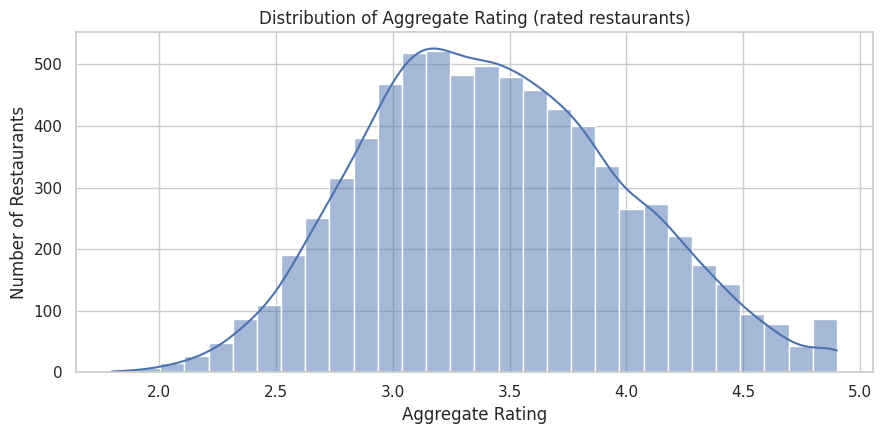

In [4]:
rated = df[~df["Is_Unrated"]].copy()

print("Rated restaurants:", len(rated), "of", len(df))
display(rated["Aggregate rating"].describe().round(2).to_frame("Aggregate rating"))

plt.figure(figsize=(9, 4.5))
sns.histplot(rated["Aggregate rating"], bins=30, kde=True, color="#4C72B0")
plt.title("Distribution of Aggregate Rating (rated restaurants)")
plt.xlabel("Aggregate Rating")
plt.ylabel("Number of Restaurants")
plt.tight_layout()
plt.show()

## 4. Exploratory Analysis of Likely Drivers

**Purpose:** Examine how the main candidate features relate to the rating before modeling. Votes are shown on a log scale because they are heavily right-skewed.

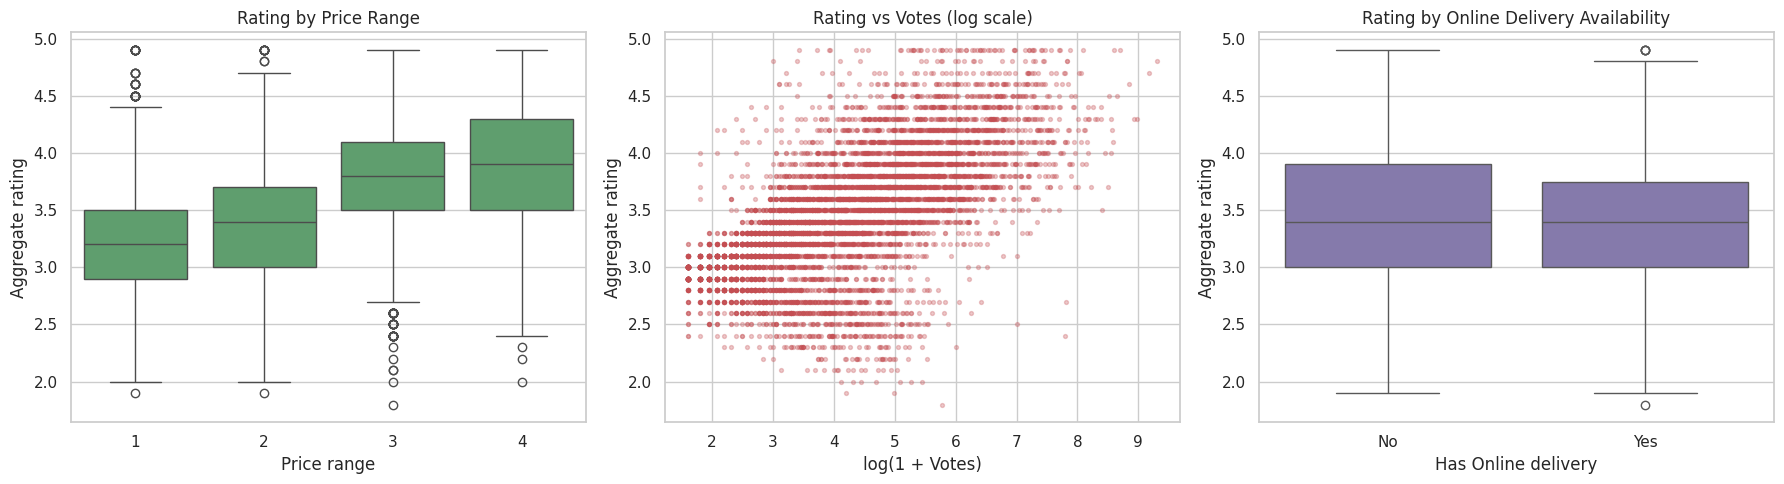

Correlation of rating with log(votes): 0.649
Correlation of rating with price range: 0.403


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(data=rated, x="Price range", y="Aggregate rating", color="#55A868", ax=axes[0])
axes[0].set_title("Rating by Price Range")

axes[1].scatter(np.log1p(rated["Votes"]), rated["Aggregate rating"], s=8, alpha=0.3, color="#C44E52")
axes[1].set_title("Rating vs Votes (log scale)")
axes[1].set_xlabel("log(1 + Votes)")
axes[1].set_ylabel("Aggregate rating")

sns.boxplot(data=rated, x="Has Online delivery", y="Aggregate rating", color="#8172B3", ax=axes[2])
axes[2].set_title("Rating by Online Delivery Availability")

plt.tight_layout()
plt.show()

print("Correlation of rating with log(votes): %.3f" % np.corrcoef(np.log1p(rated["Votes"]), rated["Aggregate rating"])[0, 1])
print("Correlation of rating with price range: %.3f" % rated[["Price range", "Aggregate rating"]].corr().iloc[0, 1])

## 5. Feature Engineering and Preprocessing

**Purpose:** Prepare model features without leaking information across validation folds. A custom scikit-learn transformer is fitted inside each pipeline. It learns the country-median cost references, the 15 most common cuisines, and the 15 most common cities using only the training partition for that fit—including each cross-validation fold.

| Feature | Treatment | Reason |
|---|---|---|
| `Latitude`, `Longitude` | `(0, 0)` set to missing, then median-imputed; add `Has_Coords` | Placeholder coordinates are not real locations |
| `Votes` | `log(1 + Votes)` | Heavy right skew |
| `Average Cost for two` | Log cost relative to the country median learned on the current training fold | Raw costs use different currencies |
| `Cuisines` | Number of listed cuisines plus 15 fixed indicator slots for the most frequent cuisines learned during each fit | Handles multi-valued text with a stable output shape |
| `Country Code`, `City` | Country one-hot encoded; top 15 cities retained and others grouped as `Other` | Controls sparse high-cardinality features |
| Yes/No columns | Encoded as 1/0 | Model-ready binary features |
| Numeric features | Median imputation and standard scaling | Supports the linear baseline and is acceptable for tree models |

The engineered feature names are fixed across folds, while the actual cuisine and city categories and country-cost medians are learned within each fold. This avoids the preprocessing leakage identified during review.


In [6]:
# Keep raw predictors here. All learned feature engineering happens inside the Pipeline.
model_df = rated.copy()
raw_feature_cols = [
    "Country Code", "City", "Longitude", "Latitude", "Cuisines",
    "Average Cost for two", "Has Table booking", "Has Online delivery",
    "Is delivering now", "Price range", "Votes"
]
X = model_df[raw_feature_cols].copy()
y = model_df["Aggregate rating"].copy()

numeric_features = (
    ["Longitude", "Latitude", "Has_Coords", "Price range", "Cost_Rel", "N_Cuisines", "Votes_Log",
     "Has_Table_booking", "Has_Online_delivery", "Is_delivering_now"]
    + [f"Cuisine_{i:02d}" for i in range(1, 16)]
)
categorical_features = ["Country", "City_Group"]

preprocessor = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])

print("Rows used for modeling:", len(model_df))
print("Raw feature count:", len(raw_feature_cols))
print("Engineered numeric feature slots:", len(numeric_features))
print("Categorical engineered features:", categorical_features)


Rows used for modeling: 7403
Raw feature count: 11
Engineered numeric feature slots: 25
Categorical engineered features: ['Country', 'City_Group']


## 6. Train/Test Split

**Purpose:** Hold out 20% of the data for final evaluation. All fitting, including the country-median cost reference, uses the training set only, so the test set stays unseen.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("The test set remains held out; learned feature engineering is fitted inside each model pipeline.")

feature_engineering = RestaurantFeatureEngineer(top_n_cuisines=15, top_n_cities=15)
preprocessor = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])


Training rows: 5922 | Test rows: 1481
The test set remains held out; learned feature engineering is fitted inside each model pipeline.


## 7. Model Training and Comparison

**Purpose:** Train several regression algorithms and compare them fairly.

**Method:**
- **Mean predictor:** Always predicts the average rating. Any useful model must beat it.
- **Linear Regression** and **Decision Tree** (the examples named in the task), plus **Random Forest** and **Gradient Boosting**.
- Models are compared with **5-fold cross-validation on the training set** and selected on cross-validated RMSE, not on the test set. The test set is used once, afterwards.
- Metrics: **MSE**, **RMSE** and **MAE** (lower is better) and **R-squared** (higher is better).

In [8]:
models = {
    "Mean predictor (baseline)": DummyRegressor(),
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=8, min_samples_leaf=10, random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, model in models.items():
    pipe = Pipeline([("features", RestaurantFeatureEngineer()), ("prep", preprocessor), ("model", model)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv,
                            scoring=("neg_root_mean_squared_error", "r2"))
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    rows.append({
        "Model": name,
        "CV RMSE": -scores["test_neg_root_mean_squared_error"].mean(),
        "CV R2": scores["test_r2"].mean(),
        "Test MSE": mean_squared_error(y_test, pred),
        "Test RMSE": mean_squared_error(y_test, pred) ** 0.5,
        "Test MAE": mean_absolute_error(y_test, pred),
        "Test R2": r2_score(y_test, pred),
    })

comparison = pd.DataFrame(rows).sort_values("CV RMSE").reset_index(drop=True)
display(comparison.round(3))

best_name = comparison.loc[0, "Model"]
print("Best model by cross-validated RMSE:", best_name)

,Model,CV RMSE,CV R2,Test MSE,Test RMSE,Test MAE,Test R2
0,Random Forest,0.347,0.603,0.107,0.326,0.240,0.655
1,Gradient Boosting,0.347,0.602,0.112,0.334,0.252,0.638
2,Linear Regression,0.358,0.576,0.121,0.348,0.261,0.609
3,Decision Tree,0.376,0.532,0.128,0.357,0.264,0.587
4,Mean predictor (baseline),0.551,-0.002,0.309,0.556,0.455,-0.000


Best model by cross-validated RMSE: Random Forest


## 8. Hyperparameter Tuning and Final Evaluation

**Purpose:** Tune the best-performing model type on the training set only, then evaluate the final model once on the held-out test set.

In [9]:
rf_pipe = Pipeline([
    ("features", RestaurantFeatureEngineer()),
    ("prep", preprocessor),
    ("model", RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE)),
])

param_grid = {
    "model__max_depth": [None, 15],
    "model__min_samples_leaf": [1, 3, 5],
    "model__max_features": [0.5, 1.0],
}

search = GridSearchCV(rf_pipe, param_grid, cv=3, scoring="neg_root_mean_squared_error", n_jobs=-1)
search.fit(X_train, y_train)

print("Best parameters:", search.best_params_)
print("Best cross-validated RMSE: %.3f" % -search.best_score_)

final_model = search.best_estimator_
y_pred = final_model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
print("\nFINAL MODEL: TEST SET PERFORMANCE")
print("MSE       : %.3f" % mse)
print("RMSE      : %.3f" % mse ** 0.5)
print("MAE       : %.3f" % mean_absolute_error(y_test, y_pred))
print("R-squared : %.3f" % r2_score(y_test, y_pred))
print("Baseline (mean predictor) RMSE: %.3f" % (mean_squared_error(y_test, np.full(len(y_test), y_train.mean())) ** 0.5))

Best parameters: {'model__max_depth': None, 'model__max_features': 0.5, 'model__min_samples_leaf': 3}
Best cross-validated RMSE: 0.345

FINAL MODEL: TEST SET PERFORMANCE
MSE       : 0.105
RMSE      : 0.324
MAE       : 0.238
R-squared : 0.661
Baseline (mean predictor) RMSE: 0.556


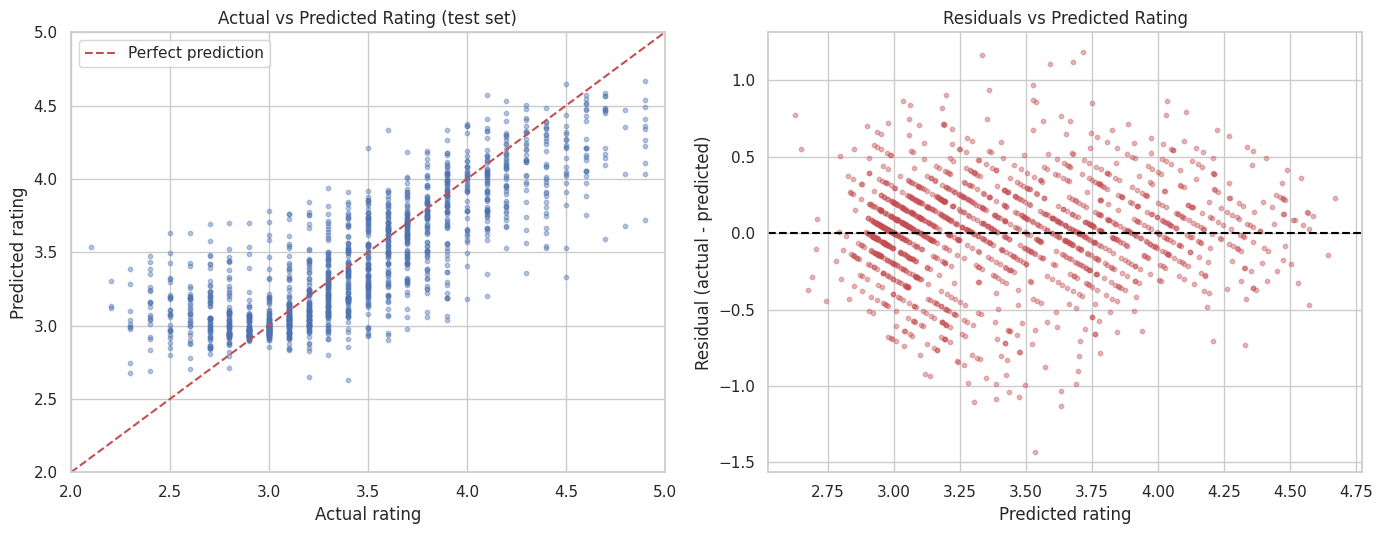

Error by actual rating band (positive Mean_Error = model under-predicts):


,Restaurants,MAE,Mean_Error
Rating band,,,
Below 2.5,34,0.769,-0.769
2.5 to 3.5,763,0.210,-0.096
3.5 to 4.0,413,0.207,0.087
Above 4.0,271,0.295,0.246


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

axes[0].scatter(y_test, y_pred, s=10, alpha=0.4, color="#4C72B0")
lims = [min(y_test.min(), y_pred.min()) - 0.1, max(y_test.max(), y_pred.max()) + 0.1]
axes[0].plot(lims, lims, "r--", label="Perfect prediction")
axes[0].set_xlim(lims); axes[0].set_ylim(lims)
axes[0].set_title("Actual vs Predicted Rating (test set)")
axes[0].set_xlabel("Actual rating")
axes[0].set_ylabel("Predicted rating")
axes[0].legend()

residuals = y_test - y_pred
axes[1].scatter(y_pred, residuals, s=10, alpha=0.4, color="#C44E52")
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set_title("Residuals vs Predicted Rating")
axes[1].set_xlabel("Predicted rating")
axes[1].set_ylabel("Residual (actual - predicted)")

plt.tight_layout()
plt.show()

# Error by actual rating band
bands = pd.cut(y_test, bins=[0, 2.5, 3.5, 4.0, 5.0], labels=["Below 2.5", "2.5 to 3.5", "3.5 to 4.0", "Above 4.0"], right=False)
band_table = (
    pd.DataFrame({"Rating band": bands, "Absolute error": (y_test - y_pred).abs(), "Error": residuals})
    .groupby("Rating band", observed=True)
    .agg(Restaurants=("Error", "count"), MAE=("Absolute error", "mean"), Mean_Error=("Error", "mean"))
    .round(3)
)
print("Error by actual rating band (positive Mean_Error = model under-predicts):")
display(band_table)

## 9. Feature Importance and Interpretation

**Purpose:** Identify which features most influence the predicted rating.

**Methods:**
- **Permutation importance** (on the test set): shuffles one feature at a time and measures how much R-squared drops. A large drop means the model relies on that feature. It is more reliable than the built-in Random Forest importance, which favors high-cardinality features.
- **Linear regression coefficients** (on standardized features): show the *direction* of each effect.

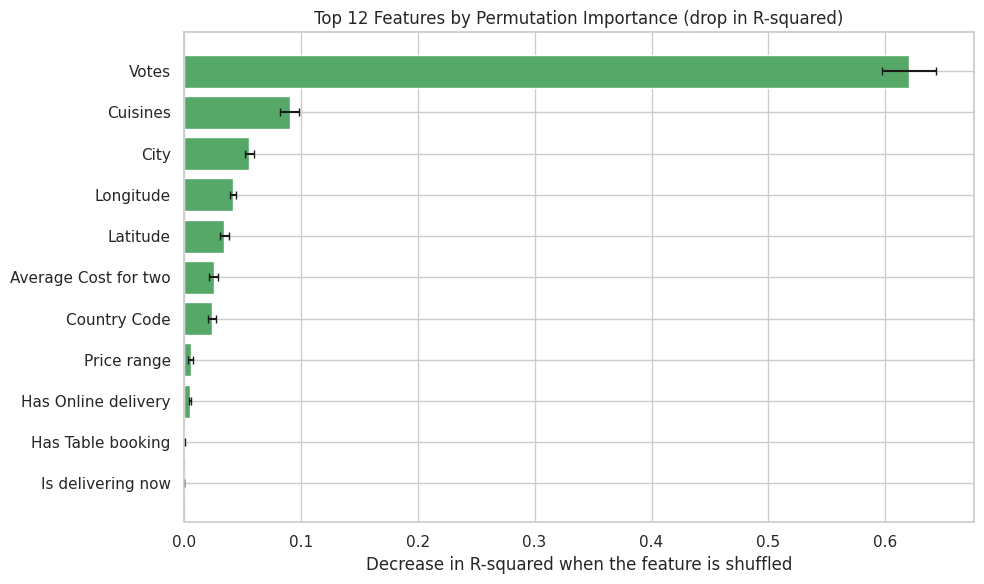

,Feature,Importance,Std
0,Votes,0.6205,0.0231
1,Cuisines,0.0905,0.0079
2,City,0.0559,0.0040
3,Longitude,0.0424,0.0026
4,Latitude,0.0346,0.0039
5,Average Cost for two,0.0255,0.0037
6,Country Code,0.0241,0.0033
7,Price range,0.0061,0.0021
8,Has Online delivery,0.0053,0.0012
9,Has Table booking,0.0007,0.0004


In [11]:
perm = permutation_importance(
    final_model, X_test, y_test, n_repeats=10, random_state=RANDOM_STATE, scoring="r2", n_jobs=-1
)
importance = (
    pd.DataFrame({"Feature": X_test.columns, "Importance": perm.importances_mean, "Std": perm.importances_std})
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

top = importance.head(12).iloc[::-1]
plt.figure(figsize=(10, 6))
plt.barh(top["Feature"], top["Importance"], xerr=top["Std"], color="#55A868", capsize=3)
plt.title("Top 12 Features by Permutation Importance (drop in R-squared)")
plt.xlabel("Decrease in R-squared when the feature is shuffled")
plt.tight_layout()
plt.show()

display(importance.head(12).round(4))

In [12]:
lin_pipe = Pipeline([
    ("features", RestaurantFeatureEngineer()),
    ("prep", preprocessor),
    ("model", LinearRegression())
]).fit(X_train, y_train)
transformed_names = lin_pipe.named_steps["prep"].get_feature_names_out()
coefs = pd.DataFrame({
    "Feature": transformed_names,
    "Coefficient": lin_pipe.named_steps["model"].coef_,
})
coefs = coefs.reindex(coefs["Coefficient"].abs().sort_values(ascending=False).index).reset_index(drop=True)
print("Linear-model coefficients after preprocessing (coefficient sign indicates direction; one-hot categories are relative to the encoded reference structure):")
display(coefs.head(15).round(3))


Linear-model coefficients after preprocessing (coefficient sign indicates direction; one-hot categories are relative to the encoded reference structure):


,Feature,Coefficient
0,cat__Country_14,-0.407
1,cat__City_Group_London,0.301
2,cat__City_Group_Guwahati,0.299
3,cat__Country_162,0.281
4,num__Votes_Log,0.277
5,cat__Country_208,0.268
6,cat__City_Group_Noida,-0.253
7,cat__Country_30,0.237
8,cat__City_Group_Valdosta,-0.230
9,cat__Country_215,0.195


## 10. Sensitivity Checks

**Purpose:** Test how much the results depend on two decisions made earlier: keeping the vote count as a feature, and excluding unrated restaurants. The same tuned Random Forest settings are reused in each variant.

In [13]:
best_params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}

def evaluate_variant(data, drop_votes=False, label=""):
    d = data.copy()
    Xv = d[raw_feature_cols].copy()
    if drop_votes:
        # Drop vote count from the raw input; a dedicated estimator wrapper is not needed.
        Xv = Xv.drop(columns=["Votes"])
    yv = d["Aggregate rating"].copy()
    Xa, Xb, ya, yb = train_test_split(Xv, yv, test_size=0.2, random_state=RANDOM_STATE)

    if drop_votes:
        # Keep the same engineered schema with Votes replaced by a constant zero.
        Xa = Xa.copy(); Xb = Xb.copy()
        Xa["Votes"] = 0
        Xb["Votes"] = 0
        Xa = Xa[raw_feature_cols]; Xb = Xb[raw_feature_cols]

    nums = numeric_features
    prep = ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), nums),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ])
    pipe = Pipeline([
        ("features", RestaurantFeatureEngineer()),
        ("prep", prep),
        ("model", RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE, **best_params)),
    ])
    pipe.fit(Xa, ya)
    pr = pipe.predict(Xb)
    return {"Variant": label, "Rows": len(d), "Test RMSE": mean_squared_error(yb, pr) ** 0.5,
            "Test MAE": mean_absolute_error(yb, pr), "Test R2": r2_score(yb, pr)}

variants = pd.DataFrame([
    evaluate_variant(df[~df["Is_Unrated"]], False, "Primary: rated restaurants, with votes"),
    evaluate_variant(df[~df["Is_Unrated"]], True, "Rated restaurants, without votes (votes neutralized)"),
    evaluate_variant(df, False, "All restaurants incl. unrated (misleading)"),
])
display(variants.round(3))


,Variant,Rows,Test RMSE,Test MAE,Test R2
0,"Primary: rated restaurants, with votes",7403,0.324,0.238,0.661
1,"Rated restaurants, without votes (votes neutra...",7403,0.374,0.290,0.547
2,All restaurants incl. unrated (misleading),9551,0.294,0.192,0.962


**How to read this table:** Removing `Votes` lowers R-squared, so the vote count is informative, but the model still explains a good share of the variation from other features. Including unrated restaurants produces a much higher R-squared that looks impressive but is misleading: the model simply learns that restaurants with 3 or fewer votes have a rating of 0. That is why the primary model uses rated restaurants only.

## 11. Summary Statistics and Conclusion

**Purpose:** Recompute the headline numbers from the executed results, so every figure in the conclusion can be verified. Section 7 reports the *untuned* candidate models and Section 8 reports the *tuned* Random Forest on the held-out test set. These are separate experiments and are labelled separately.

In [14]:
final_r2 = r2_score(y_test, y_pred)
final_rmse = mean_squared_error(y_test, y_pred) ** 0.5
final_mae = mean_absolute_error(y_test, y_pred)
base_rmse = mean_squared_error(y_test, np.full(len(y_test), y_train.mean())) ** 0.5

print(f"Restaurants: {len(df):,} | rated and modeled: {len(model_df):,} | unrated excluded: {int(df['Is_Unrated'].sum()):,}")
print(f"Best model by CV: {best_name} | tuned parameters: {search.best_params_}")
print(f"Test R-squared: {final_r2:.3f} | RMSE: {final_rmse:.3f} | MAE: {final_mae:.3f} | baseline RMSE: {base_rmse:.3f}")
print("Top 5 features:", ", ".join(importance['Feature'].head(5)))
print("\nTest R-squared by model:")
print(comparison[["Model", "Test R2"]].round(3).to_string(index=False))

Restaurants: 9,551 | rated and modeled: 7,403 | unrated excluded: 2,148
Best model by CV: Random Forest | tuned parameters: {'model__max_depth': None, 'model__max_features': 0.5, 'model__min_samples_leaf': 3}
Test R-squared: 0.661 | RMSE: 0.324 | MAE: 0.238 | baseline RMSE: 0.556
Top 5 features: Votes, Cuisines, City, Longitude, Latitude

Test R-squared by model:
                    Model  Test R2
            Random Forest    0.655
        Gradient Boosting    0.638
        Linear Regression    0.609
            Decision Tree    0.587
Mean predictor (baseline)   -0.000


## Conclusion and Insights

### Key Findings

1. **Model performance:** The tuned Random Forest is the primary candidate because model selection is based on cross-validated RMSE. Its final held-out test MAE, RMSE, and R-squared are printed in Section 8; use those freshly computed values after running this corrected notebook.
2. **Model comparison:** Section 7 compares the baseline, Linear Regression, Decision Tree, Random Forest, and Gradient Boosting. Cross-validation RMSE is used to rank candidate models, while the test set is reserved for final evaluation.
3. **Feature interpretation:** Section 9 reports permutation importance on the held-out test set and linear-model coefficients. These describe predictive associations, not causal effects.
4. **Rating coverage:** The primary model excludes restaurants with rating 0 because the audit shows these are unrated entries with very few votes, rather than genuine low ratings. Section 10 demonstrates why including them can make performance look misleadingly strong.
5. **Preprocessing integrity:** Country-relative cost, frequent-cuisine indicators, and city grouping are learned inside the pipeline. Cross-validation folds therefore fit these transformations using only their own training partitions.

### Limitations

- **Votes are post-review information.** The model with votes is useful for estimating ratings of existing restaurants, but it is not suitable as-is for a brand-new restaurant. Section 10 includes a vote-neutralized comparison.
- The relationships are associations, not causes. Votes may reflect popularity and review activity rather than cause higher ratings.
- The dataset is geographically concentrated, so performance in other countries and cities may differ.
- Rare rating values have fewer examples, which limits reliability at the extremes.
- The dataset has no customer, review-text, or time information, which could improve predictions if available.

### Future Improvements

1. Use nested validation or a larger, repeated cross-validation design to estimate model-selection uncertainty.
2. Add text features from restaurant names and cuisines as a separate, carefully validated experiment.
3. Try gradient-boosting libraries such as XGBoost or LightGBM with a controlled search space.
4. Evaluate separately for Delhi-NCR and other regions, and across rating bands, to test transferability.
5. Build a dedicated new-restaurant model that excludes post-review information such as vote count.
